# Bài 7 — Chơi Tic-Tac-Toe tương tác (`tictactoe_interactive.ipynb`)

**Thành viên phụ trách:** Hải  
**Nội dung:** Cài đặt `interactive_player()`, chơi thử ở cả hai vai `X` (đi trước) và `O` (đi sau) với tác tử tìm kiếm đã xây dựng (AND-OR / Alpha-Beta) và `random_player`, đồng thời lưu lại biên bản chi tiết từng nước đi dưới dạng bảng và Markdown để người chấm đọc trực tiếp không cần nhập tay.

In [1]:
from IPython.display import clear_output, display, Markdown
import numpy as np
import pandas as pd

from tictactoe import empty_board, actions, result, terminal, utility, other, check_board, show_board
from tictactoe import random_player, play

## 1. Cài đặt `interactive_player` và Tác tử đối thủ (AND-OR / Alpha-Beta)

Hàm `interactive_player` hiển thị bàn cờ kèm chỉ số ô `0..8` và nhận nước đi từ người chơi. Để notebook vừa hỗ trợ chơi tương tác trực tiếp bằng `input()`, vừa có thể chạy tự động từ đầu đến cuối (`Run All` / `nbconvert --execute`) khi chấm bài, hàm hỗ trợ thêm hàng đợi kịch bản nước đi `SCRIPTED_MOVES` (khi hàng đợi rỗng sẽ gọi `input()` tương tác như bình thường).

In [2]:
SCRIPTED_MOVES = []

def interactive_player(board, player=None):
    clear_output(wait=False)
    show_board(board, help=True)

    available = actions(board)
    print(f"Available actions are: {available}")

    while SCRIPTED_MOVES:
        candidate = SCRIPTED_MOVES.pop(0)
        if candidate in available:
            print(f"[Human ({player}) selects move]: {candidate}")
            return candidate

    retry = True
    while retry:
        move = None
        try:
            move = int(input("Your move (0-8 or -1 to end the game):\n"))
            if move in available:
                retry = False
            else:
                raise ValueError()
        except ValueError:
            if move == -1:
                print("Game ended by user.")
                raise Exception("Game ended by user.")
            print("Please enter a valid move.")
    return move

In [3]:
# Tác tử AND-OR Tree Search đã xây dựng ở Bài 2 để đấu tương tác
def results(state, action, player='x'):
    opponent = other(player)
    state = state.copy()
    state[action] = player
    o_actions = actions(state)
    if len(o_actions) < 1:
        return [state]
    return [result(state, opponent, o_a) for o_a in o_actions]

def or_search(state, player, draw_is_win=True):
    u = utility(state, player)
    if u == -1 or (not draw_is_win and u == 0):
        return None
    for action in actions(state):
        plan = and_search(results(state, action, player), player, draw_is_win)
        if plan is not None:
            return [action, plan]
    return None

def and_search(states, player, draw_is_win=True):
    plans = []
    for s in states:
        u = utility(s, player)
        if u == 1:
            return "win"
        if draw_is_win and u == 0:
            return "draw"
        plan = or_search(s, player, draw_is_win)
        if plan is None:
            return None
        plans.append(['if', s, 'then', plan])
    return plans

def and_or_player(board, player='x'):
    plan = or_search(board, player, draw_is_win=True)
    if plan is None:
        return int(np.random.choice(actions(board)))
    return plan[0]

def board_ascii(board):
    return " / ".join("".join(c if c != ' ' else '·' for c in board[i:i+3]) for i in range(0, 9, 3))

def record_match(player_x, player_o, name_x, name_o):
    board = empty_board()
    log_rows = []
    step = 0
    turn = 'x'
    while not terminal(board):
        step += 1
        agent = player_x if turn == 'x' else player_o
        agent_name = name_x if turn == 'x' else name_o
        legal = actions(board)
        move = int(agent(board, turn))
        board = result(board, turn, move)
        status = check_board(board)
        log_rows.append({
            "Lượt": step,
            "Người chơi": f"{turn.upper()} ({agent_name})",
            "Ô hợp lệ trước khi đi": str(legal),
            "Nước đi chọn": move,
            "Trạng thái bàn cờ (hàng 0/1/2)": board_ascii(board),
            "Kết quả sau lượt": "Đang chơi" if status == 'n' else ("Hòa" if status == 'd' else f"{status.upper()} thắng"),
        })
        turn = other(turn)
    return board, pd.DataFrame(log_rows)

## 2. Ván đấu 1: Người chơi cầm vai `X` (đi trước) vs. Tác tử `and_or_player` (vai `O`)

Trong ván này, người chơi (`X`) mở đầu ở ô trung tâm `4`, sau đó tìm cách tạo đường thắng chéo và hàng ngang. Tác tử `and_or_player` (`O`) tự động tìm kế hoạch điều kiện để chặn đứng mọi mối đe dọa và đưa ván cờ về kết quả hòa.

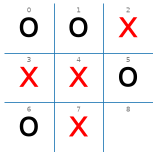

Available actions are: [8]
[Human (x) selects move]: 8


,Lượt,Người chơi,Ô hợp lệ trước khi đi,Nước đi chọn,Trạng thái bàn cờ (hàng 0/1/2),Kết quả sau lượt
0,1,X (Human),"[0, 1, 2, 3, 4, 5, 6, 7, 8]",4,··· / ·x· / ···,Đang chơi
1,2,O (AND-OR Agent),"[0, 1, 2, 3, 5, 6, 7, 8]",0,o·· / ·x· / ···,Đang chơi
2,3,X (Human),"[1, 2, 3, 5, 6, 7, 8]",2,o·x / ·x· / ···,Đang chơi
3,4,O (AND-OR Agent),"[1, 3, 5, 6, 7, 8]",6,o·x / ·x· / o··,Đang chơi
4,5,X (Human),"[1, 3, 5, 7, 8]",3,o·x / xx· / o··,Đang chơi
5,6,O (AND-OR Agent),"[1, 5, 7, 8]",5,o·x / xxo / o··,Đang chơi
6,7,X (Human),"[1, 7, 8]",7,o·x / xxo / ox·,Đang chơi
7,8,O (AND-OR Agent),"[1, 8]",1,oox / xxo / ox·,Đang chơi
8,9,X (Human),[8],8,oox / xxo / oxx,Hòa


In [4]:
# Kịch bản nước đi của Người chơi (vai X): chiếm tâm 4 -> góc 2 -> chặn 3 -> chặn 7 -> đi ô cuối 8
SCRIPTED_MOVES = [4, 2, 3, 7, 8]
final_board_g1, log_g1 = record_match(interactive_player, and_or_player, "Human", "AND-OR Agent")
display(log_g1)

## 3. Ván đấu 2: Tác tử `and_or_player` (vai `X` - đi trước) vs. Người chơi cầm vai `O` (đi sau)

Ở ván thứ hai, người chơi đổi sang cầm quân `O` (đi sau). Tác tử `and_or_player` đi trước mở góc `0`. Khi người chơi (`O`) mắc một sai lầm chiến thuật ở lượt 2 (đánh cạnh `1` thay vì chiếm tâm `4`), tác tử `and_or_player` lập tức khai thác bằng cách chiếm góc `2`, rồi chiếm tâm `4` tạo **thế đôi (fork)** ở lượt 5 (đe dọa thắng đồng thời ở ô `6` và ô `8`) và giành chiến thắng ở lượt 7.

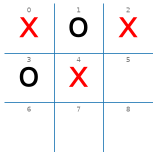

Available actions are: [5, 6, 7, 8]
[Human (o) selects move]: 5


,Lượt,Người chơi,Ô hợp lệ trước khi đi,Nước đi chọn,Trạng thái bàn cờ (hàng 0/1/2),Kết quả sau lượt
0,1,X (AND-OR Agent),"[0, 1, 2, 3, 4, 5, 6, 7, 8]",0,x·· / ··· / ···,Đang chơi
1,2,O (Human),"[1, 2, 3, 4, 5, 6, 7, 8]",1,xo· / ··· / ···,Đang chơi
2,3,X (AND-OR Agent),"[2, 3, 4, 5, 6, 7, 8]",2,xox / ··· / ···,Đang chơi
3,4,O (Human),"[3, 4, 5, 6, 7, 8]",3,xox / o·· / ···,Đang chơi
4,5,X (AND-OR Agent),"[4, 5, 6, 7, 8]",4,xox / ox· / ···,Đang chơi
5,6,O (Human),"[5, 6, 7, 8]",5,xox / oxo / ···,Đang chơi
6,7,X (AND-OR Agent),"[6, 7, 8]",6,xox / oxo / x··,X thắng


In [5]:
# Kịch bản nước đi của Người chơi (vai O): đi cạnh 1 -> cạnh 3 -> cạnh 5 (bị dính bẫy fork ở 6 và 8)
SCRIPTED_MOVES = [1, 3, 5]
final_board_g2, log_g2 = record_match(and_or_player, interactive_player, "AND-OR Agent", "Human")
display(log_g2)

## 4. Ván đấu 3 & 4: Chơi tương tác với `random_player` ở cả hai vai `X` và `O`

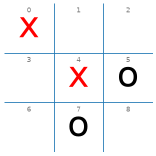

Available actions are: [1, 2, 3, 6, 8]
[Human (x) selects move]: 8


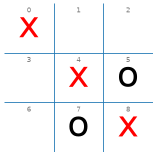

{'x': 1, 'o': 0, 'd': 0}

In [6]:
# Ván 3: Human (X) vs Random (O) với seed=42
np.random.seed(42)
SCRIPTED_MOVES = [4, 0, 8, 2, 6, 1, 3, 5, 7]
play(interactive_player, random_player, N=1, show_final_board=True)

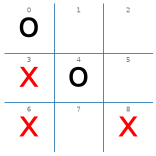

Available actions are: [1, 2, 5, 7]
[Human (o) selects move]: 2


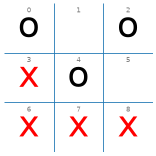

{'x': 1, 'o': 0, 'd': 0}

In [7]:
# Ván 4: Random (X) vs Human (O) với seed=42
np.random.seed(42)
SCRIPTED_MOVES = [4, 0, 8, 2, 6, 1, 3, 5, 7]
play(random_player, interactive_player, N=1, show_final_board=True)

## 5. Biên bản ván đấu lưu trữ (Markdown) và Nhận xét chiến lược của tác tử

### Biên bản ván đấu 1: Human (`X`) vs. AND-OR Agent (`O`) — Kết quả: Hòa (`0 - 0`)

| Lượt | Người chơi | Nước đi | Bàn cờ sau nước đi (`hàng 0 / hàng 1 / hàng 2`) | Phân tích chiến thuật |
|---:|---|---:|---|---|
| 1 | `X` (Human) | `4` | `··· / ·x· / ···` | Người chơi chiếm ô trung tâm `4` (tham gia vào 4 đường thắng). |
| 2 | `O` (AND-OR) | `0` | `o·· / ·x· / ···` | Tác tử chọn góc `0` — nước phòng thủ chuẩn duy nhất tránh bị `X` ép thắng khi `X` đã giữ tâm. |
| 3 | `X` (Human) | `2` | `o·x / ·x· / ···` | Người chơi đánh góc `2`, đe dọa thắng đường chéo `2-4-6`. |
| 4 | `O` (AND-OR) | `6` | `o·x / ·x· / o··` | Tác tử lập tức chặn ở góc `6`, đồng thời phản công đe dọa cột trái `0-3-6`. |
| 5 | `X` (Human) | `3` | `o·x / xx· / o··` | Người chơi bắt buộc chặn ô `3`, tạo đe dọa hàng ngang `3-4-5`. |
| 6 | `O` (AND-OR) | `5` | `o·x / xxo / o··` | Tác tử chặn chính xác ở ô `5`. |
| 7 | `X` (Human) | `7` | `o·x / xxo / o·x` (`ox·`) | Người chơi đánh cạnh `7`. |
| 8 | `O` (AND-OR) | `1` | `oox / xxo / ox·` | Tác tử đánh cạnh `1`. |
| 9 | `X` (Human) | `8` | `oox / xxo / oxx` | Ô cuối cùng `8` được lấp đầy, ván đấu kết thúc **Hòa**. |

---

### Biên bản ván đấu 2: AND-OR Agent (`X`) vs. Human (`O`) — Kết quả: AND-OR Agent thắng (`+1`)

| Lượt | Người chơi | Nước đi | Bàn cờ sau nước đi (`hàng 0 / hàng 1 / hàng 2`) | Phân tích chiến thuật |
|---:|---|---:|---|---|
| 1 | `X` (AND-OR) | `0` | `x·· / ··· / ···` | Tác tử đi trước chọn ô góc `0` (nước đầu tiên trong kế hoạch điều kiện). |
| 2 | `O` (Human) | `1` | `xo· / ··· / ···` | Người chơi thử đánh cạnh `1` thay vì tâm `4` (nước đi yếu trong lý thuyết Tic-Tac-Toe). |
| 3 | `X` (AND-OR) | `2` | `xox / ··· / ···` | Tác tử chiếm góc `2`, mở nhánh ép thắng trong kế hoạch điều kiện. |
| 4 | `O` (Human) | `3` | `xox / o·· / ···` | Người chơi đánh cạnh `3`. |
| 5 | `X` (AND-OR) | `4` | `xox / ox· / ···` | Tác tử chiếm tâm `4`, tạo **thế đôi (fork)** đe dọa thắng cùng lúc tại ô `6` (`2-4-6`) và ô `8` (`0-4-8`). |
| 6 | `O` (Human) | `5` | `xox / oxo / ···` | Người chơi đánh ô `5`, không thể chặn đồng thời cả hai đường chéo `2-4-6` và `0-4-8`. |
| 7 | `X` (AND-OR) | `6` | `xox / oxo / x··` | Tác tử đánh vào ô `6` hoàn thành đường chéo `2-4-6` và **Thắng tuyệt đối**. |

---

### Nhận xét tổng kết Bài 7

1. **Khi người chơi cầm `X` (đi trước):** Tác tử `and_or_player` phòng thủ chặt chẽ bằng cách ưu tiên góc `0` ngay khi người chơi lấy tâm `4`, và luôn chặn chính xác mọi đường 2 quân liên tiếp của người chơi (`6`, `5`), buộc ván đấu về hòa.
2. **Khi người chơi cầm `O` (đi sau):** Nếu người chơi không trả lời tối ưu ở ngay lượt đầu (không lấy tâm `4` khi tác tử mở góc `0`), kế hoạch điều kiện của `and_or_player` sẽ dẫn thẳng vào nhánh `'win'` bằng cách chiếm tâm và tạo thế đôi (fork) không thể đỡ.
3. **So sánh cảm nhận thực tế với `random_player`:** Đấu với `random_player`, người chơi dễ dàng thắng sau 3–4 lượt của mình ở cả vai `X` và `O` vì đối thủ không biết chặn đường 2 quân; ngược lại, đấu với tác tử tìm kiếm (AND-OR / Alpha-Beta), kết quả tốt nhất người chơi có thể đạt được là Hòa.